**GitHub Link (contains .ipynb):**  https://github.com/avinashsriram1/ADSP-31011-Statistical-Models-for-Data-Science/tree/main/Assignment%202

# Problem 1: Explore Welch's Two-Sample t-Test by Simulation

In [28]:
# Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(123456)

# Baseline parameters
n, mu, sigma, alpha = 30, 1, 1, 0.05

In [29]:
# Question 1A

x = rng.normal(0, 1, size=n)
y = rng.normal(mu, sigma, size=n)

t_stat, p_value = stats.ttest_ind(x, y, equal_var=False)

print(f"Welch's t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4g}")

# p value is lower than alpha value so is statistically significant test

Welch's t-statistic: -3.8686
p-value: 0.0002798


In [30]:
# Question 1B

n1, n2 = len(x), len(y)

x_bar, y_bar = x.mean(), y.mean()
s1_sq, s2_sq = x.var(ddof=1), y.var(ddof=1)

se1_sq = s1_sq / n1
se2_sq = s2_sq / n2
SE = np.sqrt(se1_sq + se2_sq)

t_manual = (x_bar - y_bar) / SE

nu = (se1_sq + se2_sq) ** 2 / (se1_sq ** 2 / (n1 - 1) + se2_sq ** 2 / (n2 - 1))

p_manual = 2 * stats.t.sf(abs(t_manual), df=nu)

print(f"Sample means: x_bar = {x_bar:.4f}, y_bar = {y_bar:.4f}")
print(f"Sample variances: s1^2 = {s1_sq:.4f}, s2^2 = {s2_sq:.4f}")
print(f"SE = {SE:.4f}")
print(f"t-statistic: {t_manual:.4f}")
print(f"Welch-Satterthwaite df: {nu:.4f}")
print(f"p-value: {p_manual:.4g}")

print(f"\nComparison to 1A: We see that the t-statistic (-3.8686) and the p-value (0.0002798) match between the scipy and the manual tests.")

Sample means: x_bar = 0.2473, y_bar = 1.0633
Sample variances: s1^2 = 0.6805, s2^2 = 0.6542
SE = 0.2109
t-statistic: -3.8686
Welch-Satterthwaite df: 57.9775
p-value: 0.0002798

Comparison to 1A: We see that the t-statistic (-3.8686) and the p-value (0.0002798) match between the scipy and the manual tests.


Intuitive Prediction: As sigma increases, the t-stat goes toward 0 and p-value increases
   sigma  mean_t  mean_p
  0.0500 -5.5905  0.0002
  5.3105 -1.1049  0.3563
 10.5711 -0.5545  0.4564
 15.8316 -0.3539  0.4967
 21.0921 -0.2822  0.4926
 26.3526 -0.2471  0.4913
 31.6132 -0.1806  0.4851
 36.8737 -0.1693  0.4933
 42.1342 -0.2123  0.4832
 47.3947 -0.0277  0.5028
 52.6553 -0.1440  0.5069
 57.9158 -0.1597  0.4977
 63.1763 -0.1289  0.4984
 68.4368 -0.1140  0.4943
 73.6974 -0.0762  0.4890
 78.9579 -0.0817  0.4868
 84.2184 -0.1060  0.4853
 89.4789 -0.0552  0.4939
 94.7395 -0.0788  0.4985
100.0000 -0.0890  0.4967


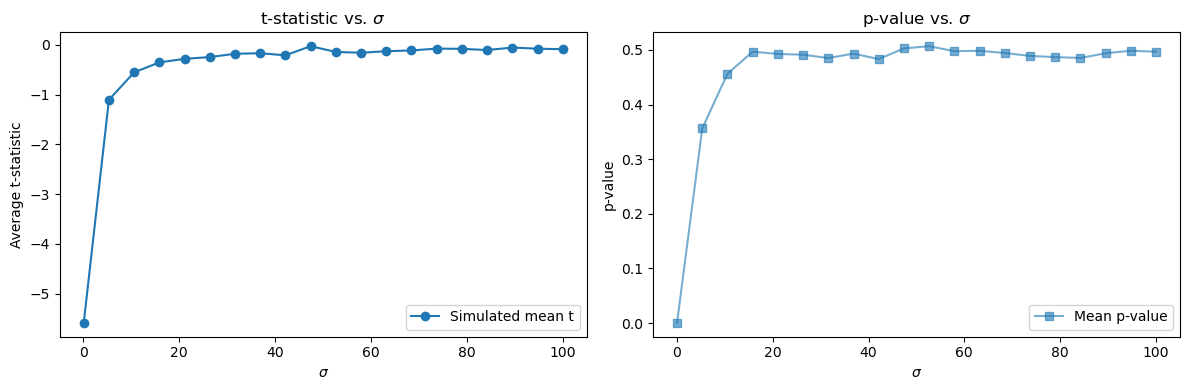

We can see based on the plot and the table, that as the value of sigma increases, the t-statistic approaches 0 and the p-value increases


In [31]:
# Question 1C

print(f"Intuitive Prediction: As sigma increases, the t-stat goes toward 0 and p-value increases")

sigmas = np.linspace(.05, 100, 20)
reps = 1000

rows = []
for s in sigmas:
    x_sim = rng.normal(0, 1, size=(reps, n))
    y_sim = rng.normal(mu, s, size=(reps, n))
    t_sim, p_sim = stats.ttest_ind(x_sim, y_sim, axis=1, equal_var=False)
    rows.append({
        "sigma": s,
        "mean_t": t_sim.mean(),
        "mean_p": p_sim.mean(),
    })

results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))

t_theory = -mu * np.sqrt(n) / np.sqrt(1 + sigmas ** 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

axes[0].plot(results["sigma"], results["mean_t"], marker="o", label="Simulated mean t")
axes[0].set_xlabel(r"$\sigma$")
axes[0].set_ylabel("Average t-statistic")
axes[0].set_title("t-statistic vs. $\\sigma$")
axes[0].legend()

axes[1].plot(results["sigma"], results["mean_p"], marker="s", alpha=0.6, label="Mean p-value")
axes[1].set_xlabel(r"$\sigma$")
axes[1].set_ylabel("p-value")
axes[1].set_title("p-value vs. $\\sigma$")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"We can see based on the plot and the table, that as the value of sigma increases, the t-statistic approaches 0 and the p-value increases")


    n    mean_t       mean_p
   10 -0.325705 4.907157e-01
  100 -0.962790 3.842338e-01
 1000 -3.165717 2.306107e-02
10000 -9.988397 3.501211e-15


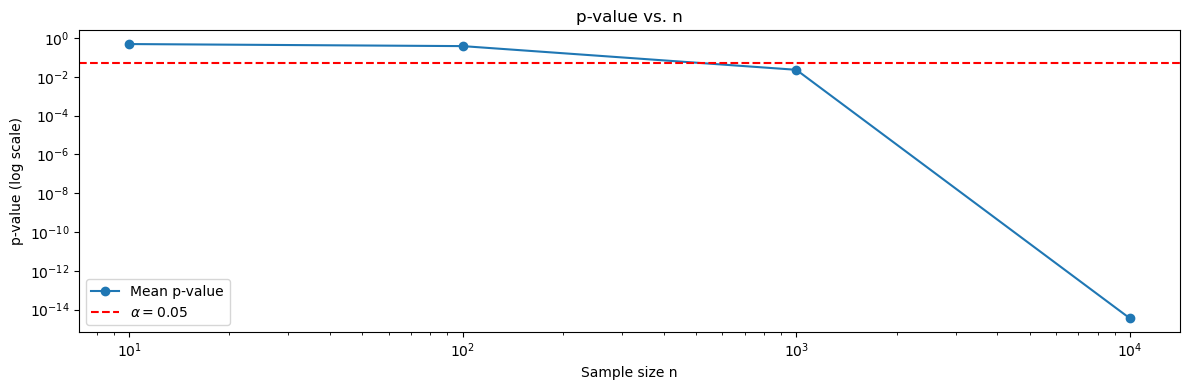

We see that as n increases, the test is able to detect the group difference. However, it takes a very large n to actually get this value as the effect of sigma is large.


In [ ]:
# Question 1D

sigma_large = 10
ns = [10, 100, 1000, 10000]
reps = 1000

rows = []
for n_i in ns:
    x_sim = rng.normal(0, 1, size=(reps, n_i))
    y_sim = rng.normal(mu, sigma_large, size=(reps, n_i))
    t_sim, p_sim = stats.ttest_ind(x_sim, y_sim, axis=1, equal_var=False)
    rows.append({
        "n": n_i,
        "mean_t": t_sim.mean(),
        "mean_p": p_sim.mean(),
    })

results_n = pd.DataFrame(rows)
print(results_n.to_string(index=False))


ns_arr = np.array(ns)
t_theory_n = -mu * np.sqrt(ns_arr) / np.sqrt(1 + sigma_large ** 2)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(results_n["n"], results_n["mean_p"], marker="o", label="Mean p-value")
ax.axhline(alpha, color="red", linestyle="--", label=r"$\alpha = 0.05$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Sample size n")
ax.set_ylabel("p-value (log scale)")
ax.set_title("p-value vs. n")
ax.legend()

plt.tight_layout()
plt.show()

print("We see that as n increases, the test is able to detect the group difference. However, it takes a very large n to actually get this value as the effect of sigma is large.")


**Question 1E:**  

A larger σ hurts the Welch t-test: as σ increases, |t| decreases and the p-value increases, because the fixed mean difference (μ = 1) is swamped by noise. This makes the group difference harder to detect, and the expected t shrinks roughly like 1/√(1 + σ²).

A larger sample size n helps: |t| grows like √n and the p-value falls toward 0, because the standard error shrinks as σ/√n. Even at σ = 10, where n = 30 fails to detect the difference, a large enough n does detect it. Sample size doesn't change σ itself. It reduces the noise in the sample means, so a large σ can always be offset with enough data, though it costs roughly (1 + σ²)/2 times as many observations.

Takeaway: a failure to reject at small n and large σ reflects low power, not evidence that the groups are equal.

# Problem 2: Is There a "Santa Claus Rally"?

**Question 2A (Hypotheses):**  
State the null and alternative hypotheses in terms of μ_rally and μ_rest. Should the alternative be one-sided or two-sided? Justify your choice.

**Answer:**  
TODO

In [33]:
# Question 2B

import yfinance as yf

# TODO: download ^GSPC daily prices from 1949-12-01 through 2026-01-31
# TODO: compute simple daily returns r_d = P_d / P_{d-1} - 1
# TODO: print first/last few rows and the number of trading days


ModuleNotFoundError: No module named 'yfinance'

In [ ]:
# Question 2C

# TODO: for each year t = 1950..2025:
#   W_t = last 5 trading days of December of t + first 2 trading days of January of t+1
#   R_t = 3rd trading day of January of t up to (excluding) the last 5 trading days of December
#   compute mean daily return of each; record |W_t| and |R_t|
# TODO: DataFrame with one row per year; display first and last five rows


**Question 2C (follow-up):**  
Why is it important to use a per-day average rather than the total return over each set of days?

**Answer:**  
TODO

In [ ]:
# Question 2D

# TODO: histograms of rest vs rally (common x-axis, mark each sample mean)
# TODO: numerical summaries (mean, sd, skewness, kurtosis, min/max), additional EDA plots (e.g., boxplot, scatter rest vs rally, time series by year)

# TODO: comment on location, spread, skewness, outliers


**Question 2E1:**  
Which test is more appropriate: Welch's two-sample t-test or the paired t-test? Think about how the samples are constructed and about the variances of the two groups.

**Answer:**  
TODO

In [ ]:
# Question 2E2

# TODO: Welch's t-test and paired t-test on rally vs rest
# TODO: correlation between rest and rally across years


**Question 2E3:**  
Does the result surprise you? Explain.

**Answer:**  
TODO

In [ ]:
# Question 2F

periods = {"Full (1950-2025)": (1950, 2025), "1950-1987": (1950, 1987), "1988-2025": (1988, 2025)}

# TODO: for each period: mean rally, mean rest, correlation, Welch test, paired test
# TODO: table of results side by side

# TODO: comment on stability over time and notable observations


**Generative AI Use:**  

TODO